# Error analysis of the logistic regression model

The TF-IDF + logistic regression model from `01_ml_model.ipynb` is run on the full Fakeddit test set (59,319 posts). The wrong predictions are pulled out and grouped to see where and why the model fails, the model is then tried on a different dataset (LIAR2), and two improvements are measured: a "numbers missing" flag and a tuned decision threshold.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from pathlib import Path
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, ConfusionMatrixDisplay

DATA = Path("../data/multimodal_only_samples-20261006T085257Z-1-001/multimodal_only_samples")
LIAR = Path("../data/liar2")
FIG = Path("../report/figures"); FIG.mkdir(parents=True, exist_ok=True)  # grafikus iskart saugom ataskaitai
MODEL_PATH = Path("../models/logreg_tfidf.joblib")
FLAG_PATH = Path("../models/logreg_missing_flag.joblib")
FEATURES = ["clean_title", "score", "num_comments", "upvote_ratio"]
SUBTYPES = {0: "true", 1: "satire/parody", 2: "misleading content", 3: "imposter content",
            4: "false connection", 5: "manipulated content"}  # Fakeddit 6 klasiu pavadinimai
SEED = 42

## 1. Load data and model
The model is the trained pipeline saved by the first notebook, loaded as is. `subreddit` and the 6-way label are loaded only to group the errors afterwards; the model never sees them.

In [2]:
test = pd.read_csv(DATA / "multimodal_test_public.tsv", sep="\t", usecols=FEATURES + ["2_way_label", "6_way_label", "subreddit"])
X_test, y_test = test[FEATURES], test["2_way_label"].to_numpy()
model = joblib.load(MODEL_PATH)  # jau ismokytas pirmame darbe, cia nieko nemokom
test.shape

(59319, 7)

## 2. Predictions and errors
Every test post gets a probability of being real. With the default 0.5 threshold there are two kinds of error:
* **missed fake** - a fake post called real;
* **false alarm** - a real post called fake.

In [3]:
def scores(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    return {"accuracy": accuracy_score(y, pred), "macro F1": f.mean(), "fake recall": r[0], "real recall": r[1]}

proba = model.predict_proba(X_test)[:, 1]  # tikimybe, kad irasas tikras
pred = (proba >= 0.5).astype(int)
test["proba"], test["pred"] = proba, pred
test["error"] = np.select([(y_test == 0) & (pred == 1), (y_test == 1) & (pred == 0)], ["missed fake", "false alarm"], "correct")
print(pd.Series(scores(y_test, pred)).round(4))
test["error"].value_counts()

accuracy       0.8487
macro F1       0.8441
fake recall    0.8454
real recall    0.8537
dtype: float64


error
correct        50343
missed fake     5538
false alarm     3438
Name: count, dtype: int64

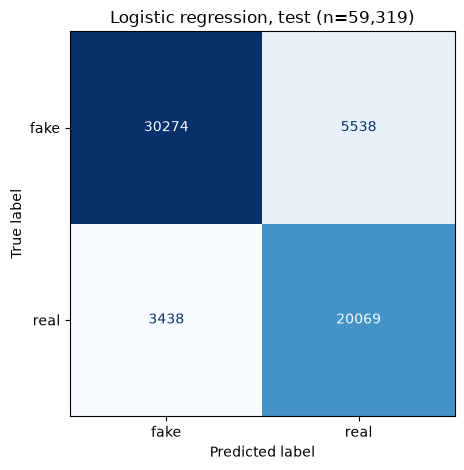

In [4]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["fake", "real"], cmap="Blues", values_format="d", colorbar=False)
plt.title("Logistic regression, test (n=59,319)"); plt.tight_layout(); plt.savefig(FIG / "err_confusion.png", dpi=120); plt.show()

In [5]:
errors = test[test["error"] != "correct"]
errors[["clean_title", "subreddit", "proba", "error"]].sample(10, random_state=SEED)

,clean_title,subreddit,proba,error
23334,beauty had no birthdays,mildlyinteresting,0.319002,false alarm
671,artist interpretation of an ancient squid species,misleadingthumbnails,0.583399,missed fake
45031,help me,pareidolia,0.554192,missed fake
14003,canadian boxes,pareidolia,0.650219,missed fake
26762,star fox is down,psbattle_artwork,0.599080,missed fake
15222,against the monopoly of violence our right to ...,propagandaposters,0.887315,missed fake
38074,another day another dollar,psbattle_artwork,0.563279,missed fake
36719,the guy on the far left looks like larry david...,psbattle_artwork,0.525363,missed fake
53749,mark zuckerberg with an o face,photoshopbattles,0.261749,false alarm
34203,these japanese kitkats,mildlyinteresting,0.491410,false alarm


## 3. Where the errors are
The error rate is compared across groups of posts: whether the engagement numbers are present, the fake subtype (6-way label), the subreddit, the title length and how sure the model was.

In [6]:
def error_table(by):
    t = pd.crosstab(by, test["error"])
    t["posts"] = t.sum(axis=1)
    t["error rate"] = 1 - t["correct"] / t["posts"]
    t["share of all errors"] = (t["posts"] - t["correct"]) / len(errors)
    return t.drop(columns="correct").sort_values("error rate", ascending=False)

test["numbers"] = np.where(test["num_comments"].isna(), "missing", "present")  # tusti langeliai yra tik viename netikrame subreddit
error_table(test["numbers"]).round(4)

error,false alarm,missed fake,posts,error rate,share of all errors
numbers,,,,,
present,3438,4177,41847,0.1820,0.8484
missing,0,1361,17472,0.0779,0.1516


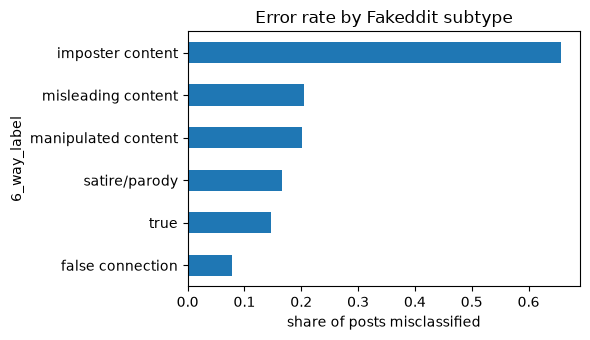

error,false alarm,missed fake,posts,error rate,share of all errors
6_way_label,,,,,
imposter content,0,805,1224,0.6577,0.0897
misleading content,0,2323,11297,0.2056,0.2588
manipulated content,0,463,2305,0.2009,0.0516
satire/parody,0,586,3514,0.1668,0.0653
true,3438,0,23507,0.1463,0.3830
false connection,0,1361,17472,0.0779,0.1516


In [7]:
by_type = error_table(test["6_way_label"].map(SUBTYPES))
by_type["error rate"].sort_values().plot.barh(figsize=(6, 3.5), title="Error rate by Fakeddit subtype")
plt.xlabel("share of posts misclassified"); plt.tight_layout(); plt.savefig(FIG / "err_by_subtype.png", dpi=120); plt.show()
by_type.round(4)

In [8]:
error_table(test["subreddit"]).round(4)

error,false alarm,missed fake,posts,error rate,share of all errors
subreddit,,,,,
subredditsimulator,0,794,1198,0.6628,0.0885
misleadingthumbnails,0,715,1662,0.4302,0.0797
subsimulatorgpt2,0,11,26,0.4231,0.0012
confusing_perspective,0,324,846,0.3830,0.0361
pic,231,0,619,0.3732,0.0257
savedyouaclick,0,267,813,0.3284,0.0297
satire,0,112,402,0.2786,0.0125
theonion,0,203,803,0.2528,0.0226
usnews,111,0,613,0.1811,0.0124


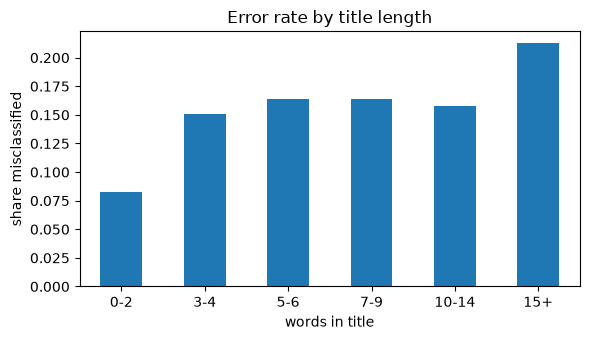

error,false alarm,missed fake,posts,error rate,share of all errors
clean_title,,,,,
0-2,237,570,9777,0.0825,0.0899
3-4,660,965,10809,0.1503,0.1810
5-6,656,966,9876,0.1642,0.1807
7-9,879,1123,12217,0.1639,0.2230
10-14,743,1049,11329,0.1582,0.1996
15+,263,865,5311,0.2124,0.1257


In [9]:
words = test["clean_title"].fillna("").str.split().str.len()
length = pd.cut(words, [-1, 2, 4, 6, 9, 14, 1000], labels=["0-2", "3-4", "5-6", "7-9", "10-14", "15+"])
by_len = error_table(length).sort_index()
by_len["error rate"].plot.bar(rot=0, figsize=(6, 3.5), title="Error rate by title length")
plt.xlabel("words in title"); plt.ylabel("share misclassified"); plt.tight_layout(); plt.savefig(FIG / "err_by_length.png", dpi=120); plt.show()
by_len.round(4)

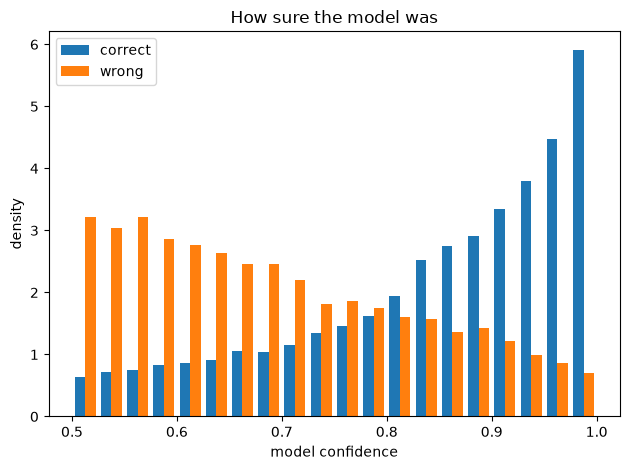

,correct,wrong
count,50343.000,8976.000
mean,0.844,0.694
std,0.131,0.134
min,0.500,0.500
25%,0.763,0.580
50%,0.879,0.673
75%,0.952,0.795
max,1.000,1.000


In [10]:
test["confidence"] = np.maximum(proba, 1 - proba)  # kiek modelis tikras savo atsakymu, nesvarbu kuria kryptimi
ok = test["error"] == "correct"
plt.hist([test.loc[ok, "confidence"], test.loc[~ok, "confidence"]], bins=20, range=(0.5, 1), density=True, label=["correct", "wrong"])
plt.xlabel("model confidence"); plt.ylabel("density"); plt.legend(); plt.title("How sure the model was")
plt.tight_layout(); plt.savefig(FIG / "err_confidence.png", dpi=120); plt.show()
pd.DataFrame({"correct": test.loc[ok, "confidence"].describe(), "wrong": test.loc[~ok, "confidence"].describe()}).round(3)

In [11]:
for t in [0.6, 0.8, 0.9]:
    print(f"errors with confidence above {t}: {(test.loc[~ok, 'confidence'] > t).mean():.1%}")

errors with confidence above 0.6: 69.2%
errors with confidence above 0.8: 24.3%
errors with confidence above 0.9: 9.4%


## 4. Why the model was wrong
Logistic regression adds up one weight per word (and per number). For each post, multiplying the word's TF-IDF value by its weight shows how much that word pushed the post towards real (+) or fake (-). Summing these pushes over the wrong posts shows which words cause the most errors.

In [12]:
Xt = model[:-1].transform(X_test)  # tie patys 50 003 stulpeliai, kuriuos mato modelis
names = pd.Index(model[:-1].get_feature_names_out()).str.split("__", n=1).str[1]
contrib = Xt.multiply(model[-1].coef_[0]).tocsr()  # kiek kiekvienas zodis ar skaicius pastume irasa link tikra (+) ar netikra (-)
known = Xt[:, :-3].getnnz(axis=1)  # kiek antrastes zodziu modelis is viso pazista
test["known words"] = known
print("Posts with no known words:", (known == 0).sum())
error_table(pd.Series(np.where(known == 0, "no known words", "has known words"), index=test.index)).round(4)

Posts with no known words: 1897


error,false alarm,missed fake,posts,error rate,share of all errors
row_0,,,,,
has known words,3405,5532,57422,0.1556,0.9957
no known words,33,6,1897,0.0206,0.0043


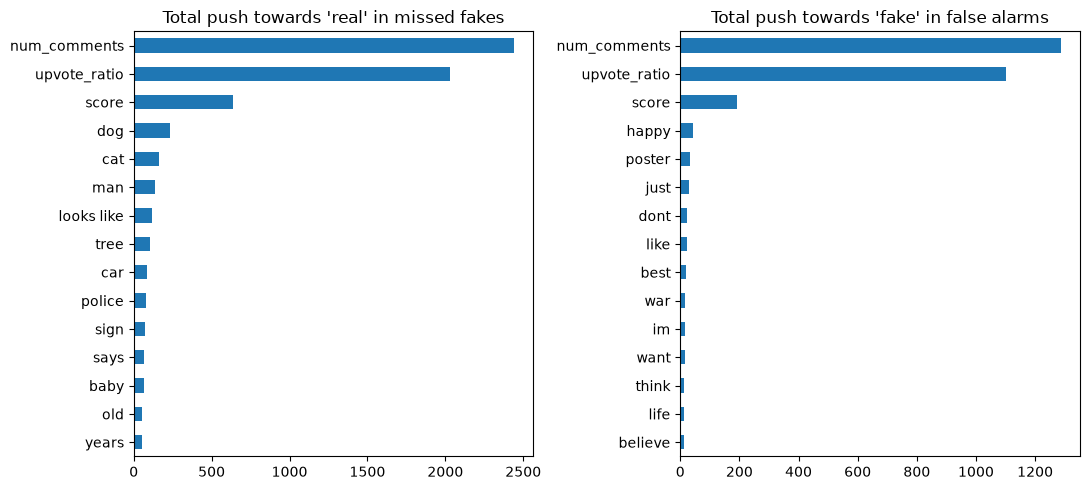

,missed fake,false alarm
0,num_comments (2443.5),num_comments (1287.4)
1,upvote_ratio (2031.0),upvote_ratio (1100.2)
2,score (638.1),score (192.5)
3,dog (230.6),happy (43.3)
4,cat (160.0),poster (32.9)
5,man (135.7),just (29.1)
6,looks like (117.5),dont (24.3)
7,tree (105.7),like (22.2)
8,car (82.4),best (18.9)
9,police (75.7),war (16.9)


In [13]:
def wrong_pushers(kind, n=15):
    rows = contrib[(test["error"] == kind).to_numpy()]
    sign = 1 if kind == "missed fake" else -1  # praleista netikra: kalti tie, kas stume link tikra; klaidingas pavojus - atvirksciai
    total = np.asarray((rows * sign).maximum(0).sum(axis=0)).ravel()
    return pd.Series(total, index=names).nlargest(n)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, kind, label in [(axes[0], "missed fake", "towards 'real' in missed fakes"), (axes[1], "false alarm", "towards 'fake' in false alarms")]:
    wrong_pushers(kind).sort_values().plot.barh(ax=ax, title=f"Total push {label}")
plt.tight_layout(); plt.savefig(FIG / "err_wrong_words.png", dpi=120); plt.show()
pd.DataFrame({k: wrong_pushers(k).round(1).reset_index().apply(lambda r: f"{r.iloc[0]} ({r.iloc[1]})", axis=1) for k in ["missed fake", "false alarm"]})

In [14]:
def pushed_by(i, k=3):
    row = contrib[i]
    s = pd.Series(row.data, index=names[row.indices])
    s = s[np.sign(s) == (1 if pred[i] == 1 else -1)]  # tik tai, kas stume link klaidingo atsakymo
    return ", ".join(f"{w} {s[w]:+.2f}" for w in s.abs().nlargest(k).index)

def worst(kind, n=10):
    rows = test[test["error"] == kind].nlargest(n, "confidence")  # labiausiai uztikrintos klaidos
    return pd.DataFrame({"title": rows["clean_title"], "subreddit": rows["subreddit"],
                         "subtype": rows["6_way_label"].map(SUBTYPES), "P(real)": rows["proba"].round(3),
                         "pushed by": [pushed_by(i) for i in rows.index]})

pd.set_option("display.max_colwidth", 80)
worst("missed fake")

,title,subreddit,subtype,P(real),pushed by
46327,five shot near minnesota protest of police killing of a respiratory illness ...,subredditsimulator,imposter content,1.000,"upvote_ratio +1.88, num_comments +1.26, police +1.12"
2358,gofundme says donors in alleged san francisco bans sales of pet food company...,subredditsimulator,imposter content,1.000,"num_comments +1.26, says +0.95, bans +0.91"
51283,trumps labor secretary admits to contact with russian bank exec was effort t...,subredditsimulator,imposter content,0.999,"upvote_ratio +2.36, num_comments +1.26, trumps +0.67"
17077,ian paisley says rape accused should have custody a los angeles gas leak lea...,subredditsimulator,imposter content,0.999,"num_comments +1.26, accused +1.06, says +0.91"
54975,putin says russia backs free syrian army pushes to recapture mosul will be m...,subredditsimulator,imposter content,0.999,"num_comments +1.26, mosul +1.06, says +0.94"
23282,if i find this sign,subredditsimulator,imposter content,0.998,"sign +5.83, num_comments +1.26, upvote_ratio +0.55"
30161,new zealand scraps sexist road sign after yearold girls plea,savedyouaclick,manipulated content,0.998,"num_comments +3.59, yearold +1.26, sign +1.23"
56238,the way the water goes perfectly gown the drain at my local grocery store,subredditsimulator,imposter content,0.998,"num_comments +1.75, way water +0.98, store +0.96"
23485,the simon wiesenthal center has identified dozens of blackclad police rappel...,subredditsimulator,imposter content,0.998,"num_comments +1.29, police +1.14, identified +0.70"
30836,cat in trouble has runin with police officer arrests sweaty suspect in theft...,subredditsimulator,imposter content,0.998,"num_comments +1.75, police +1.32, firefighters +1.21"


In [15]:
worst("false alarm")

,title,subreddit,subtype,P(real),pushed by
48468,aborigine of sakhalin island circa,photoshopbattles,true,0.004,"circa -5.96, num_comments -0.17"
26704,this hg fischer fixed xray system circa,mildlyinteresting,true,0.005,"circa -3.25, fixed -0.95, num_comments -0.17"
15452,this is where and why the whole creepy clowns thing started so here is your til,usnews,true,0.005,"til -4.39, thing -0.30, num_comments -0.17"
41127,i found this poster from in a crawl space,mildlyinteresting,true,0.008,"poster -2.44, space -0.55, upvote_ratio -0.33"
27527,hitler cant believe his eyes,photoshopbattles,true,0.008,"believe -1.39, hitler -0.78, num_comments -0.47"
42367,public masturbator to cops wait til im finished,nottheonion,true,0.009,"til -3.61, wait -0.65, im -0.62"
30856,this fashion poster from,mildlyinteresting,true,0.009,"poster -3.33, upvote_ratio -0.26, score -0.14"
25490,murica and murika,photoshopbattles,true,0.010,"murica -2.64, upvote_ratio -0.33, num_comments -0.17"
45538,italian soldiers with a machine gun circa,photoshopbattles,true,0.010,"circa -2.60, upvote_ratio -0.90, machine gun -0.29"
26555,freedom from oppression,upliftingnews,true,0.012,"oppression -1.10, freedom -1.08, num_comments -0.98"


In [16]:
rng = np.random.default_rng(SEED)
sample = test.loc[rng.choice(errors.index, 20, replace=False)]  # atsitiktines klaidos, ne tik pacios ryskiausios
pd.DataFrame({"title": sample["clean_title"], "subreddit": sample["subreddit"], "error": sample["error"],
              "P(real)": sample["proba"].round(3), "pushed by": [pushed_by(i) for i in sample.index]})

,title,subreddit,error,P(real),pushed by
46536,charybdis falls water park,psbattle_artwork,missed fake,0.797,"falls +1.32, park +0.99, water +0.84"
43259,photo taken during high noon it looks cool,mildlyinteresting,false alarm,0.432,"num_comments -0.47, photo taken -0.38, noon -0.30"
12256,a man at the drama rama concert,photoshopbattles,false alarm,0.268,"num_comments -0.47, upvote_ratio -0.46"
57933,kangaroo with ripped muscles,photoshopbattles,false alarm,0.419,num_comments -0.98
50396,this inkblot looks like my parents fighting,pareidolia,missed fake,0.988,"upvote_ratio +2.52, looks like +1.15, fighting +0.82"
45837,jeb bushs unhappy face,photoshopbattles,false alarm,0.337,"unhappy -0.27, upvote_ratio -0.20, score -0.05"
7896,saw this camel on the back of a work truck,pareidolia,missed fake,0.795,"camel +1.18, truck +1.09, work truck +0.64"
5614,when youve got a library card,psbattle_artwork,missed fake,0.582,"library +1.22, card +0.89, library card +0.33"
39091,emperor valerian captive at the court of shapur i ca,fakehistoryporn,missed fake,0.622,"court +1.89, upvote_ratio +1.12, captive +0.57"
30753,this golf course uses brown grass on its greens,confusing_perspective,missed fake,0.983,"upvote_ratio +2.36, uses +1.38, golf +0.79"


## 5. Out-of-domain test: LIAR2
LIAR2 holds short statements by US politicians, checked by PolitiFact. Labels 0-2 (pants on fire, false, barely true) count as fake, 4-5 (mostly true, true) as real, and half-true (3) is dropped. The statements are cleaned the same way as `clean_title` (lowercase, no punctuation). They have no Reddit numbers, so those are left empty and the pipeline fills them with the training median.

In [17]:
liar = pd.read_csv(LIAR / "test.csv", usecols=["label", "statement"])
liar = liar[liar["label"] != 3]  # puse tiesos nera nei tikra, nei netikra
y_liar = (liar["label"] >= 4).astype(int).to_numpy()
X_liar = pd.DataFrame({"clean_title": liar["statement"].str.lower().str.replace(r"[^\w\s]", "", regex=True),
                       "score": np.nan, "num_comments": np.nan, "upvote_ratio": np.nan})  # politiku teiginiai neturi Reddit skaiciu
liar_pred = model.predict(X_liar)
print("LIAR2 statements:", len(liar), "| fake share:", round((y_liar == 0).mean(), 4))
print("Known words per statement (median):", np.median(model[:-1].transform(X_liar)[:, :-3].getnnz(axis=1)))
print("Share predicted fake:", round((liar_pred == 0).mean(), 4))
pd.Series(scores(y_liar, liar_pred)).round(4)

LIAR2 statements: 1925 | fake share: 0.6873
Known words per statement (median): 9.0
Share predicted fake: 0.2125


accuracy       0.4161
macro F1       0.4102
fake recall    0.2298
real recall    0.8256
dtype: float64

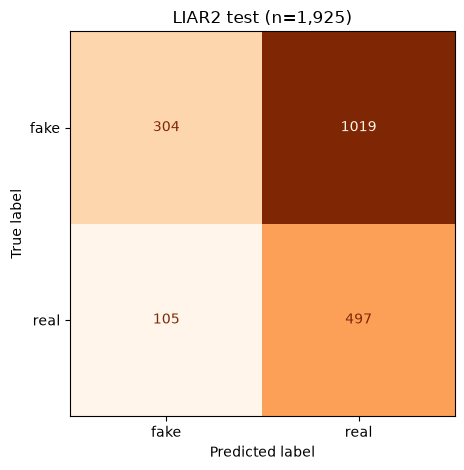

In [18]:
ConfusionMatrixDisplay.from_predictions(y_liar, liar_pred, display_labels=["fake", "real"], cmap="Oranges", values_format="d", colorbar=False)
plt.title(f"LIAR2 test (n={len(liar):,})"); plt.tight_layout(); plt.savefig(FIG / "err_liar2_confusion.png", dpi=120); plt.show()

## 6. Measured improvements
Two cheap changes are tried and scored on the same test set, on the posts that do have numbers, and on LIAR2.

**a) "Numbers missing" flag.** The imputer gets `add_indicator=True`, so besides the median fill the model gets a 0/1 column saying the numbers were empty. Everything else stays the same. Training takes about half a minute, but the model is still saved to `models/logreg_missing_flag.joblib` and loaded on later runs (delete the file to retrain).

**b) Tuned threshold.** Instead of 0.5, the threshold that gives the best macro F1 on the official validation set (`multimodal_validate.tsv`) is used. The test set is not touched while choosing it.

In [19]:
if FLAG_PATH.exists():
    flag_model = joblib.load(FLAG_PATH)  # jau ismokytas, nemokom is naujo
else:
    train = pd.read_csv(DATA / "multimodal_train.tsv", sep="\t", usecols=FEATURES + ["2_way_label"])
    flag_model = clone(model).set_params(features__meta__simpleimputer__add_indicator=True)  # prie skaiciu pridedam stulpeli 'skaiciu nebuvo'
    flag_model.fit(train[FEATURES], train["2_way_label"])
    joblib.dump(flag_model, FLAG_PATH)
    del train  # mokymo duomenu toliau nereikia, atlaisvinam atminti
flag_names = flag_model[:-1].get_feature_names_out()
pd.Series(flag_model[-1].coef_[0][-5:], index=flag_names[-5:]).round(3)  # skaiciu ir naujo stulpelio svoriai

meta__score                            -0.681
meta__num_comments                      0.886
meta__upvote_ratio                     -0.377
meta__missingindicator_num_comments   -18.011
meta__missingindicator_upvote_ratio   -18.011
dtype: float64

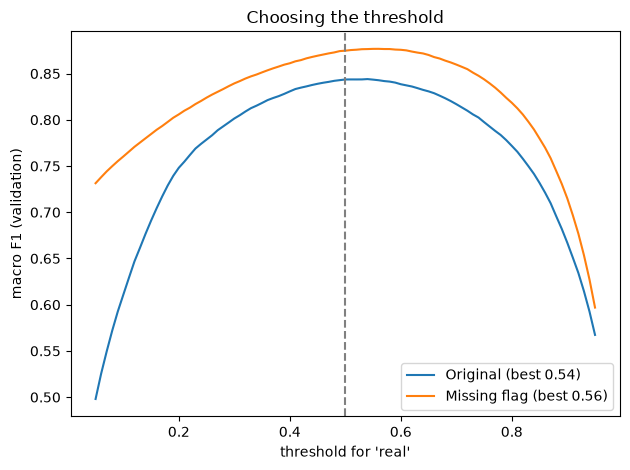

{'Original': np.float64(0.54), 'Missing flag': np.float64(0.56)}

In [20]:
val = pd.read_csv(DATA / "multimodal_validate.tsv", sep="\t", usecols=FEATURES + ["2_way_label"])
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
curves, best = {}, {}
for name, m in [("Original", model), ("Missing flag", flag_model)]:
    p = m.predict_proba(val[FEATURES])[:, 1]
    curves[name] = pd.Series([f1_score(val["2_way_label"], p >= t, average="macro") for t in grid], index=grid)
    best[name] = curves[name].idxmax()
    plt.plot(grid, curves[name], label=f"{name} (best {best[name]:.2f})")
plt.axvline(0.5, ls="--", c="gray"); plt.xlabel("threshold for 'real'"); plt.ylabel("macro F1 (validation)")
plt.legend(); plt.title("Choosing the threshold"); plt.tight_layout(); plt.savefig(FIG / "err_threshold.png", dpi=120); plt.show()
best

In [21]:
present = (test["numbers"] == "present").to_numpy()
rows = {}
for name, m in [("Original", model), ("Missing flag", flag_model)]:
    p_test, p_liar = m.predict_proba(X_test)[:, 1], m.predict_proba(X_liar)[:, 1]
    for t in [0.5, best[name]]:
        pt = (p_test >= t).astype(int)
        s = scores(y_test, pt)
        rows[(name, t)] = {**s, "errors": int((pt != y_test).sum()),
                           "missing: accuracy": accuracy_score(y_test[~present], pt[~present]),  # cia visi irasai netikri, todel macro F1 neturi prasmes
                           "present: macro F1": f1_score(y_test[present], pt[present], average="macro"),
                           "LIAR2: macro F1": scores(y_liar, (p_liar >= t).astype(int))["macro F1"],
                           "LIAR2: called fake": ((p_liar >= t) == 0).mean()}
results = pd.DataFrame(rows).T.rename_axis(["model", "threshold"])
results.round(4)

accuracy  macro F1  fake recall  real recall  errors  \
model        threshold                                                         
Original     0.50         0.8487    0.8441       0.8454       0.8537  8976.0   
             0.54         0.8504    0.8446       0.8639       0.8298  8876.0   
Missing flag 0.50         0.8754    0.8727       0.8467       0.9192  7391.0   
             0.56         0.8797    0.8761       0.8705       0.8937  7135.0   

                        missing: accuracy  present: macro F1  LIAR2: macro F1  \
model        threshold                                                          
Original     0.50                  0.9221             0.8143           0.4102   
             0.54                  0.9365             0.8118           0.4290   
Missing flag 0.50                  1.0000             0.8153           0.4073   
             0.56                  1.0000             0.8241           0.4073   

                        LIAR2: called fake  
model        threshold                      
Original     0.50                   0.2125  
             0.54                   0.2514  
Missing flag 0.50                   1.0000  
             0.56                   1.0000

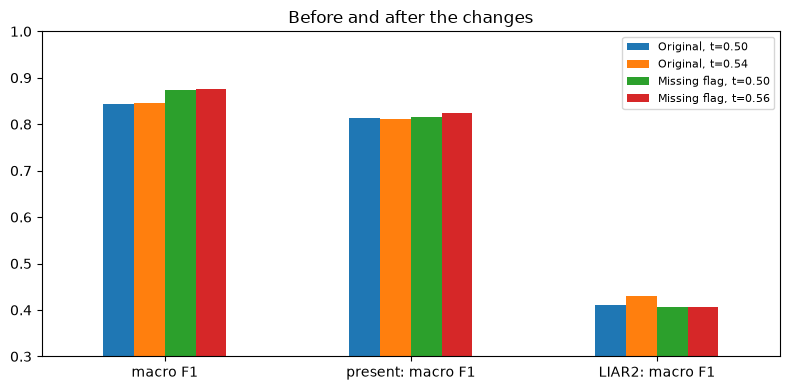

In [22]:
results[["macro F1", "present: macro F1", "LIAR2: macro F1"]].T.plot.bar(rot=0, ylim=(0.3, 1), figsize=(8, 4), title="Before and after the changes")
plt.legend([f"{m}, t={t:.2f}" for m, t in results.index], fontsize=8); plt.tight_layout(); plt.savefig(FIG / "err_improvements.png", dpi=120); plt.show()

## 7. What the results show
* **Missing flag**: the overall score jumps, but only because the model now gets every post with missing numbers right. It learned "numbers missing = fake", which holds only because all such posts come from one fake subreddit. On posts that have numbers nothing changes, and on LIAR2 (where the numbers are always missing) it calls every statement fake. This is the same shortcut the random forest found, so it is not a real improvement.
* **Tuned threshold**: a small, honest gain chosen on the validation set. It trades a little real recall for fake recall.
* **LIAR2**: the model is worse than always answering "fake". Political statements look like news headlines, and news headlines are what the model learned to call real.